# Soal 2: Klasifikasi Dataset breast-cancer.csv

**Nama:** Christina Adelia Sitinjak  
**NIM:** 42324056  
**Mata Kuliah:** 4233201 - Kecerdasan Buatan  
**Topik:** Klasifikasi K-NN dan Naive Bayes

> Letakkan file `breast-cancer.csv` di folder yang sama dengan notebook ini, lalu jalankan sel dari atas ke bawah (Run All).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset breast-cancer.csv
df = pd.read_csv('breast-cancer.csv')
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


#### Penjelasan:

Kode di atas untuk menyiapkan library yang dipakai, lalu membaca file `breast-cancer.csv` dan melihat sekilas isinya.

`pandas` (`pd`) dipakai untuk mengolah data tabel, `numpy` (`np`) untuk hitungan angka, `matplotlib.pyplot` (`plt`) dan `seaborn` (`sns`) untuk membuat grafik. Baris `pd.read_csv('breast-cancer.csv')` membaca file dan menyimpannya di variabel `df`, lalu `df.head()` menampilkan 5 baris teratas.

**Cara membaca hasil:** setiap baris adalah satu pasien. Kolom `id` adalah nomor pasien dan kolom `diagnosis` adalah hasil diagnosisnya: `M` berarti *malignant* (ganas) dan `B` berarti *benign* (jinak). Kolom-kolom sisanya adalah hasil pengukuran sel tumor, misalnya `radius_mean` (rata-rata jari-jari), `texture_mean`, `perimeter_mean` (keliling), `area_mean` (luas), dan seterusnya. Tulisan `...` di tengah tabel berarti sebagian kolom disembunyikan agar tabelnya muat di layar, bukan berarti datanya hilang.

**Catatan:** file `breast-cancer.csv` harus berada di folder yang sama dengan notebook ini.


In [2]:
# Ukuran data, jumlah missing value, dan jumlah tiap diagnosis
print("Ukuran data (baris, kolom):", df.shape)
print("Total missing value       :", df.isnull().sum().sum())
print()
print(df['diagnosis'].value_counts())

Ukuran data (baris, kolom): (569, 32)
Total missing value       : 0

diagnosis
B    357
M    212
Name: count, dtype: int64


#### Penjelasan:

Kode di atas untuk mengenali data lebih dulu: ukurannya, ada tidaknya data kosong, dan perbandingan jumlah pasien ganas dan jinak.

`df.shape` menampilkan jumlah baris dan kolom. Lalu `df.isnull().sum().sum()` menghitung jumlah sel kosong. Perintah `isnull()` menandai sel yang kosong, `sum()` pertama menjumlahkan per kolom, dan `sum()` kedua menjumlahkan semua kolom menjadi satu angka total. Baris `df['diagnosis'].value_counts()` menghitung berapa kali tiap nilai `diagnosis` muncul.

**Cara membaca hasil:** datanya berukuran **569 baris dan 32 kolom**. Total missing value **0**, jadi data lengkap dan tidak perlu diisi atau dibersihkan. Dari 569 pasien, **357 berdiagnosis B (jinak)** dan **212 berdiagnosis M (ganas)**. Jumlahnya tidak sama persis tetapi masih cukup seimbang (sekitar 63 persen dan 37 persen), jadi model tidak akan terlalu berat sebelah.


In [3]:
# Menyiapkan fitur (X) dan label (y)
# Kolom id dibuang karena hanya nomor pasien, diagnosis diubah ke angka: M (malignant) = 1, B (benign) = 0
X = df.drop(columns=['id', 'diagnosis'])
y = df['diagnosis'].map({'M': 1, 'B': 0})

print("Jumlah fitur:", X.shape[1])
print(y.value_counts())

Jumlah fitur: 30
diagnosis
0    357
1    212
Name: count, dtype: int64


#### Penjelasan:

Kode di atas untuk memisahkan data menjadi fitur (X) dan label (y). Fitur adalah informasi yang dipakai model untuk menebak, dan label adalah jawaban yang ingin ditebak.

Baris `X = df.drop(columns=['id', 'diagnosis'])` mengambil semua kolom kecuali `id` dan `diagnosis`. Kolom `id` dibuang karena hanya nomor pasien. Nomor ini tidak ada hubungannya dengan sifat tumor, dan kalau ikut dipakai bisa mengganggu model. Kolom `diagnosis` dibuang dari X karena itu adalah jawabannya, jadi tidak boleh ikut dipakai untuk menebak dirinya sendiri.

Baris `y = df['diagnosis'].map({'M': 1, 'B': 0})` mengubah label huruf menjadi angka, yaitu `M` (ganas) menjadi 1 dan `B` (jinak) menjadi 0. Model di scikit-learn bekerja dengan angka, jadi perubahan ini membuat hasilnya lebih mudah diproses. Setelah itu, `X.shape[1]` menampilkan jumlah fitur dan `y.value_counts()` memeriksa jumlah tiap label setelah diubah.

**Cara membaca hasil:** ada **30 fitur** yang dipakai. Label 0 (jinak) berjumlah 357 dan label 1 (ganas) berjumlah 212, sama dengan jumlah di langkah sebelumnya. Ini menandakan perubahan huruf ke angka berjalan benar.


In [4]:
# Membagi data: 80% latih dan 20% uji
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Data latih:", X_train.shape)
print("Data uji  :", X_test.shape)

Data latih: (455, 30)
Data uji  : (114, 30)


#### Penjelasan:

Kode di atas untuk membagi data menjadi data latih (80 persen) dan data uji (20 persen).

Data latih dipakai model untuk belajar. Data uji disimpan dulu dan dipakai untuk menguji model, seperti ujian dengan soal yang belum pernah dilihat. Dengan begitu kita tahu apakah model benar-benar bisa menebak, bukan hanya menghafal.

Fungsi `train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)` melakukan pembagiannya. Pengaturan `test_size=0.2` berarti 20 persen data jadi data uji. Pengaturan `random_state=42` mengunci pengacakan supaya hasil pembagiannya sama setiap kali dijalankan. Pengaturan `stratify=y` menjaga agar perbandingan jinak dan ganas di data latih dan data uji sama dengan data aslinya. Tanpa ini, data uji bisa kebetulan berisi terlalu banyak salah satu jenis. Fungsi ini menghasilkan empat bagian sekaligus: `X_train`, `X_test`, `y_train`, dan `y_test`.

**Cara membaca hasil:** data latih berukuran **(455, 30)**, yaitu 455 pasien dengan 30 fitur, dan data uji berukuran **(114, 30)**, yaitu 114 pasien. Jumlah 455 ditambah 114 sama dengan 569.


In [5]:
# Standarisasi fitur (khusus untuk KNN)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # belajar dari data latih saja
X_test_scaled = scaler.transform(X_test)         # data uji hanya ditransformasi

X_train_scaled[:3, :5].round(3)

array([[ 0.519,  0.892,  0.425,  0.384, -0.975],
       [-0.516, -1.64 , -0.541, -0.543,  0.476],
       [-0.368,  0.456, -0.388, -0.403, -1.433]])

#### Penjelasan:

Kode di atas untuk melakukan standarisasi fitur, yaitu menyamakan skala semua kolom. Langkah ini khusus diperlukan untuk KNN.

KNN mengelompokkan data berdasarkan jarak antar titik. Di data ini skala tiap kolom sangat berbeda. Contohnya `area_mean` bernilai ratusan sampai ribuan, sedangkan `smoothness_mean` hanya sekitar 0,05 sampai 0,16. Kalau dibiarkan, kolom yang angkanya besar akan menguasai perhitungan jarak, dan kolom yang angkanya kecil seperti tidak dianggap. `StandardScaler` mengubah tiap kolom menjadi punya rata-rata 0 dan sebaran (standar deviasi) 1, sehingga semua kolom punya peran yang adil.

Baris `scaler.fit_transform(X_train)` melakukan dua hal sekaligus: `fit` menghitung rata-rata dan sebaran dari **data latih**, dan `transform` mengubah datanya. Lalu `scaler.transform(X_test)` mengubah data uji memakai rata-rata dan sebaran yang dihitung dari data latih tadi, tanpa menghitung ulang. Hal ini penting. Kalau data uji ikut dihitung, informasi dari data uji "bocor" ke proses belajar, dan hasil ujinya jadi terlalu optimis (disebut *data leakage*).

Baris terakhir, `X_train_scaled[:3, :5].round(3)`, hanya menampilkan 3 baris dan 5 kolom pertama untuk mengintip hasilnya.

**Cara membaca hasil:** angkanya sekarang berkisar di sekitar -2 sampai 2, bukan lagi angka asli. Angka positif berarti nilainya di atas rata-rata kolom itu, dan angka negatif berarti di bawah rata-rata.

**Catatan:** Naive Bayes tidak memerlukan standarisasi, jadi nanti ia memakai data aslinya.


---
## a. Klasifikasi Menggunakan K-NN dan Naive Bayes
### KNN

K terbaik: 3 | akurasi CV: 0.9692


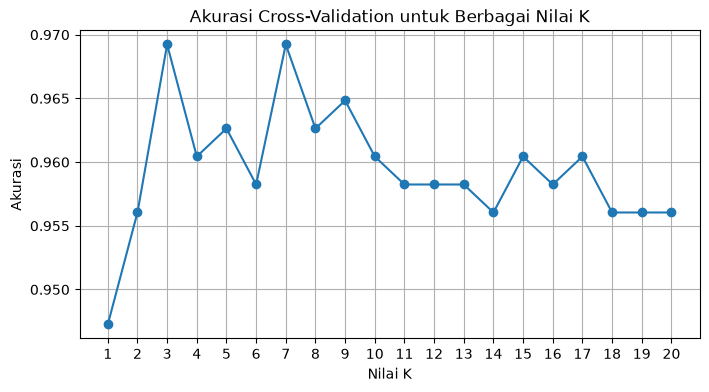

In [6]:
# a. KNN - mencari nilai K terbaik dengan cross-validation (pada data latih)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

daftar_k = range(1, 21)
skor_cv = []
for k in daftar_k:
    knn_coba = KNeighborsClassifier(n_neighbors=k)
    skor_cv.append(cross_val_score(knn_coba, X_train_scaled, y_train, cv=5).mean())

k_terbaik = list(daftar_k)[int(np.argmax(skor_cv))]
print("K terbaik:", k_terbaik, "| akurasi CV:", round(max(skor_cv), 4))

plt.figure(figsize=(8, 4))
plt.plot(daftar_k, skor_cv, marker='o')
plt.title('Akurasi Cross-Validation untuk Berbagai Nilai K')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.xticks(daftar_k)
plt.grid(True)
plt.show()

#### Penjelasan:

Kode di atas untuk mencari nilai K terbaik pada algoritma KNN. Ini adalah langkah pertama dari bagian **a (KNN)**.

KNN (*K-Nearest Neighbors*) menebak kelas sebuah data dengan melihat K tetangga terdekatnya, lalu mengambil suara terbanyak. Misalnya K = 3 dan dari 3 tetangga terdekat ada 2 yang ganas dan 1 yang jinak, maka data baru ditebak ganas. Nilai K yang terlalu kecil membuat model terlalu sensitif terhadap data yang janggal, sedangkan K yang terlalu besar membuat model terlalu kasar.

Perulangan `for k in daftar_k` mencoba K dari 1 sampai 20. Untuk tiap K, `cross_val_score(knn_coba, X_train_scaled, y_train, cv=5)` menguji model dengan *cross-validation* 5 lipatan. Data latih dibagi 5 bagian, lalu bergantian 4 bagian dipakai belajar dan 1 bagian dipakai menguji, jadi menghasilkan 5 nilai akurasi. Nilai rata-ratanya dihitung dengan `.mean()` dan dikumpulkan di daftar `skor_cv`. Keuntungannya, K dipilih tanpa menyentuh data uji, jadi data uji tetap "bersih" untuk ujian akhir.

Baris `np.argmax(skor_cv)` mencari posisi skor tertinggi, lalu dari situ diambil nilai K-nya dan disimpan di `k_terbaik`. Sisa kode menggambar grafik K terhadap akurasi.

**Cara membaca hasil:** K terbaik adalah **3** dengan akurasi cross-validation sekitar **0,9692** (96,92 persen). Di grafik, sumbu x adalah nilai K dan sumbu y adalah akurasi. Titik tertinggi menunjukkan K terbaik.


In [7]:
# a. KNN - melatih model dan menguji pada data uji
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

knn = KNeighborsClassifier(n_neighbors=k_terbaik)
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)

akurasi_knn = accuracy_score(y_test, y_pred_knn)
print("Akurasi KNN:", round(akurasi_knn, 4))
print()
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))
print()
print(classification_report(y_test, y_pred_knn, target_names=['Benign', 'Malignant']))

Akurasi KNN: 0.9386

Confusion Matrix:
[[71  1]
 [ 6 36]]

              precision    recall  f1-score   support

      Benign       0.92      0.99      0.95        72
   Malignant       0.97      0.86      0.91        42

    accuracy                           0.94       114
   macro avg       0.95      0.92      0.93       114
weighted avg       0.94      0.94      0.94       114



#### Penjelasan:

Kode di atas untuk melatih model KNN dengan K terbaik, lalu mengujinya pada data uji. Ini adalah langkah kedua dari bagian **a (KNN)**.

Baris `KNeighborsClassifier(n_neighbors=k_terbaik)` membuat model KNN dengan jumlah tetangga sesuai K terbaik tadi. `knn.fit(X_train_scaled, y_train)` melatih model memakai data latih. Lalu `knn.predict(X_test_scaled)` meminta model menebak diagnosis pasien-pasien di data uji, dan hasil tebakannya disimpan di `y_pred_knn`.

Penilaiannya memakai tiga alat. `accuracy_score(y_test, y_pred_knn)` menghitung akurasi, yaitu persentase tebakan yang benar. `confusion_matrix` membuat tabel yang menunjukkan jenis benar dan salahnya. `classification_report` menampilkan ukuran yang lebih rinci per kelas.

**Cara membaca hasil:** akurasi KNN adalah **0,9386** atau sekitar 93,9 persen, artinya 107 dari 114 pasien ditebak dengan benar.

Pada confusion matrix `[[71, 1], [6, 36]]`, baris adalah kenyataan dan kolom adalah tebakan. Baris pertama (benar-benar jinak): 71 ditebak jinak (benar) dan 1 ditebak ganas (salah). Baris kedua (benar-benar ganas): 6 ditebak jinak (salah) dan 36 ditebak ganas (benar).

Pada laporan klasifikasi, `precision` adalah seberapa tepat tebakan sebuah kelas, dan `recall` adalah seberapa banyak data asli kelas itu yang berhasil ditemukan. Untuk kelas ganas, precision-nya 0,97 dan recall-nya **0,86**. Artinya 6 pasien ganas luput dari tebakan. Dalam kasus kanker, kesalahan seperti ini yang paling berbahaya (pasien ganas dikira jinak), jadi recall kelas ganas adalah angka yang paling penting diperhatikan.


### Naive Bayes

In [8]:
# a. Naive Bayes - melatih model dan menguji pada data uji
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)

akurasi_nb = accuracy_score(y_test, y_pred_nb)
print("Akurasi Naive Bayes:", round(akurasi_nb, 4))
print()
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))
print()
print(classification_report(y_test, y_pred_nb, target_names=['Benign', 'Malignant']))

Akurasi Naive Bayes: 0.9386

Confusion Matrix:
[[72  0]
 [ 7 35]]

              precision    recall  f1-score   support

      Benign       0.91      1.00      0.95        72
   Malignant       1.00      0.83      0.91        42

    accuracy                           0.94       114
   macro avg       0.96      0.92      0.93       114
weighted avg       0.94      0.94      0.94       114



#### Penjelasan:

Kode di atas untuk melatih model Naive Bayes dan mengujinya pada data uji. Ini adalah bagian **a (Naive Bayes)**.

Naive Bayes menebak kelas dengan menghitung peluang. Algoritma ini mempelajari pola nilai tiap fitur untuk tiap kelas dari data latih, lalu untuk data baru ia menghitung peluang data itu termasuk jinak dan peluang termasuk ganas, dan memilih peluang yang lebih besar. Kata "naive" (naif) berarti algoritma menganggap setiap fitur berdiri sendiri, padahal kenyataannya tidak selalu begitu, tetapi cara sederhana ini sering tetap bekerja baik.

Varian yang dipakai adalah `GaussianNB`, yaitu Naive Bayes untuk fitur berupa angka berkelanjutan (dianggap berbentuk kurva lonceng/normal). Model dilatih dengan `nb.fit(X_train, y_train)`. Perhatikan bahwa yang dipakai adalah data **asli** (`X_train`), bukan data hasil standarisasi, karena Naive Bayes menghitung peluang per fitur secara terpisah dan tidak terpengaruh skala. Lalu `nb.predict(X_test)` menghasilkan tebakan untuk data uji. Penilaiannya memakai alat yang sama seperti pada KNN.

**Cara membaca hasil:** akurasi Naive Bayes adalah **0,9386** atau sekitar 93,9 persen, sama dengan KNN. Confusion matrix-nya `[[72, 0], [7, 35]]`. Baris pertama (benar-benar jinak): 72 ditebak jinak dan 0 salah. Baris kedua (benar-benar ganas): 7 ditebak jinak (salah) dan 35 ditebak ganas (benar).

Untuk kelas ganas, precision-nya **1,00**, artinya semua pasien yang ditebak ganas memang ganas. Namun recall-nya **0,83**, artinya 7 pasien ganas luput. Pada kelas jinak, recall-nya 1,00.


In [9]:
# a. Perbandingan KNN dan Naive Bayes
perbandingan = pd.DataFrame({
    'Model': ['KNN', 'Naive Bayes'],
    'Akurasi': [akurasi_knn, akurasi_nb]
}).round(4)
perbandingan

,Model,Akurasi
0,KNN,0.9386
1,Naive Bayes,0.9386


#### Penjelasan:

Kode di atas untuk membandingkan akurasi KNN dan Naive Bayes dalam satu tabel.

Perintah `pd.DataFrame({...})` membuat tabel dengan dua kolom: nama model dan akurasinya, yang diambil dari variabel `akurasi_knn` dan `akurasi_nb` yang sudah dihitung di sel sebelumnya. Fungsi `.round(4)` membulatkan angkanya 4 angka di belakang koma.

**Cara membaca hasil:** kedua model punya akurasi yang sama, yaitu **0,9386**. Jadi dari sisi akurasi, tidak ada yang lebih unggul. Perbedaannya ada di jenis kesalahan: KNN keliru pada 7 pasien (1 jinak ditebak ganas, 6 ganas ditebak jinak), sedangkan Naive Bayes juga keliru pada 7 pasien tetapi semuanya berupa ganas ditebak jinak. KNN sedikit lebih baik dalam menemukan pasien ganas (recall 0,86 dibanding 0,83), sedangkan Naive Bayes tidak pernah salah saat menebak ganas (precision 1,00).

**Kesimpulan:** untuk data ini kedua model sama-sama bagus (sekitar 94 persen). Karena dalam kasus kanker yang paling ditakutkan adalah pasien ganas yang tidak terdeteksi, KNN sedikit lebih aman. Perlu diingat juga bahwa data ujinya hanya 114 pasien, jadi selisih satu atau dua pasien saja sudah mengubah angka akurasi.


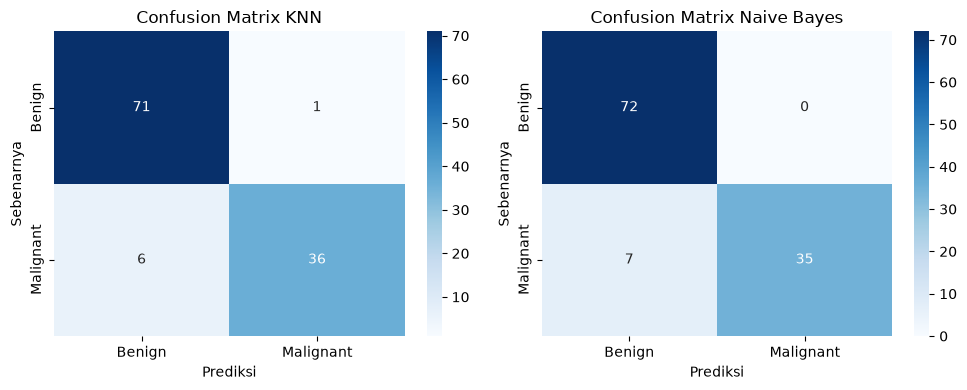

In [10]:
# Confusion matrix dalam bentuk gambar
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, pred, judul in zip(axes, [y_pred_knn, y_pred_nb], ['KNN', 'Naive Bayes']):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues',
                xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'], ax=ax)
    ax.set_title(f'Confusion Matrix {judul}')
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Sebenarnya')

plt.tight_layout()
plt.show()

#### Penjelasan:

Kode di atas untuk menampilkan confusion matrix KNN dan Naive Bayes dalam bentuk gambar berwarna, supaya lebih mudah dibandingkan sekilas.

Baris `plt.subplots(1, 2, figsize=(10, 4))` menyiapkan dua grafik berdampingan. Perulangan `for ax, pred, judul in zip(...)` memasangkan grafik kiri dengan hasil KNN dan grafik kanan dengan hasil Naive Bayes. Di dalamnya, `sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', ...)` menggambar confusion matrix berupa kotak berwarna. Pengaturan `annot=True` menuliskan angka di tiap kotak, `fmt='d'` membuat angkanya bulat, dan `cmap='Blues'` memakai warna biru, yang makin tua berarti angkanya makin besar. Pengaturan `xticklabels` dan `yticklabels` memberi nama kelas pada sumbu.

**Cara membaca hasil:** sumbu mendatar adalah tebakan model dan sumbu tegak adalah kenyataan. Kotak diagonal (kiri atas dan kanan bawah) adalah tebakan yang benar, dan kotak di luar diagonal adalah tebakan yang salah. Kotak diagonal berwarna tua dan berisi angka besar, yaitu 71 dan 36 pada KNN, serta 72 dan 35 pada Naive Bayes. Kotak kiri bawah (ganas ditebak jinak) bernilai 6 pada KNN dan 7 pada Naive Bayes. Kotak kanan atas (jinak ditebak ganas) bernilai 1 pada KNN dan 0 pada Naive Bayes.


---
## b. Prediksi Data Baru (Malignant atau Benign)

In [11]:
# b. Prediksi data baru dari soal (2 digit terakhir NIM = 56)
NIM2 = 56

fitur_soal = ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
              'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean']

data_baru = pd.DataFrame({
    'radius_mean':          [NIM2, NIM2, NIM2, NIM2, NIM2, 15.4, 17.6, 19.8, 21.5, 23.2],
    'texture_mean':         [14.3, 21.4, 19.1, 24.3, 12.6, NIM2, NIM2, NIM2, NIM2, NIM2],
    'perimeter_mean':       [85.5, 115.3, 95.4, 105.5, 70.8, 125.8, 90.2, 110.4, 100.5, 120.3],
    'area_mean':            [520.1, 950.2, 730.3, 820.4, 430.2, 1100.5, 670.4, 890.1, 780.6, 1020.7],
    'smoothness_mean':      [0.09, 0.12, 0.10, 0.11, 0.08, 0.13, 0.09, 0.12, 0.11, 0.14],
    'compactness_mean':     [0.12, 0.18, 0.15, 0.17, 0.10, 0.20, 0.14, 0.19, 0.16, 0.21],
    'concavity_mean':       [0.15, 0.22, 0.20, 0.25, 0.12, 0.30, 0.18, 0.27, 0.22, 0.28],
    'concave points_mean':  [0.08, 0.10, 0.09, 0.12, 0.06, 0.15, 0.08, 0.11, 0.10, 0.13],
})
data_baru

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean
0,56.0,14.3,85.5,520.1,0.09,0.12,0.15,0.08
1,56.0,21.4,115.3,950.2,0.12,0.18,0.22,0.10
2,56.0,19.1,95.4,730.3,0.10,0.15,0.20,0.09
3,56.0,24.3,105.5,820.4,0.11,0.17,0.25,0.12
4,56.0,12.6,70.8,430.2,0.08,0.10,0.12,0.06
5,15.4,56.0,125.8,1100.5,0.13,0.20,0.30,0.15
6,17.6,56.0,90.2,670.4,0.09,0.14,0.18,0.08
7,19.8,56.0,110.4,890.1,0.12,0.19,0.27,0.11
8,21.5,56.0,100.5,780.6,0.11,0.16,0.22,0.10
9,23.2,56.0,120.3,1020.7,0.14,0.21,0.28,0.13


#### Penjelasan:

Kode di atas untuk bagian **b**, yaitu menyiapkan data baru dari soal yang akan diklasifikasikan sebagai *malignant* (ganas) atau *benign* (jinak).

Pada soal, sebagian sel tabel berisi tulisan "2 digit terakhir NIM". NIM kamu adalah 42324056, jadi dua digit terakhirnya adalah **56**. Angka ini disimpan di variabel `NIM2 = 56` dan dipakai pada sel-sel yang diminta. Pada data nomor 1 sampai 5, nilai yang diminta ada di kolom `radius_mean`. Pada data nomor 6 sampai 10, nilainya ada di kolom `texture_mean`. Kolom lainnya diisi sesuai angka di tabel soal.

Daftar `fitur_soal` berisi 8 nama kolom yang ada di tabel soal. Perhatikan bahwa nama kolom `concave points_mean` ditulis persis seperti di dataset (ada spasi, bukan garis bawah), karena nama kolom harus sama supaya cocok dengan data latih. Perintah `pd.DataFrame({...})` lalu menyusun tabel berisi 10 data baru. Setiap kolom diberi 10 nilai, berurutan dari data pertama sampai kesepuluh.

**Cara membaca hasil:** tabel yang tampil adalah 10 pasien baru dengan 8 pengukuran, sesuai tabel pada soal. Nilai 56 tampak di kolom `radius_mean` pada lima baris pertama, dan di kolom `texture_mean` pada lima baris terakhir.


In [12]:
# b. Melatih ulang model hanya dengan 8 fitur yang tersedia pada data baru
X8_train = X_train[fitur_soal]
X8_test = X_test[fitur_soal]

scaler8 = StandardScaler()
X8_train_scaled = scaler8.fit_transform(X8_train)
X8_test_scaled = scaler8.transform(X8_test)

# Mencari K terbaik dengan cross-validation
skor8 = []
for k in range(1, 21):
    skor8.append(cross_val_score(KNeighborsClassifier(n_neighbors=k), X8_train_scaled, y_train, cv=5).mean())
k8 = list(range(1, 21))[int(np.argmax(skor8))]

knn8 = KNeighborsClassifier(n_neighbors=k8).fit(X8_train_scaled, y_train)
nb8 = GaussianNB().fit(X8_train, y_train)

print("K terbaik (8 fitur):", k8)
print("Akurasi KNN (data uji)        :", round(accuracy_score(y_test, knn8.predict(X8_test_scaled)), 4))
print("Akurasi Naive Bayes (data uji):", round(accuracy_score(y_test, nb8.predict(X8_test)), 4))

K terbaik (8 fitur): 10
Akurasi KNN (data uji)        : 0.9386
Akurasi Naive Bayes (data uji): 0.8947


#### Penjelasan:

Kode di atas untuk melatih ulang model KNN dan Naive Bayes hanya dengan 8 fitur yang tersedia pada data baru.

Alasannya begini. Model pada bagian a dilatih dengan 30 fitur, sedangkan data baru di soal hanya punya 8 fitur. Model tidak bisa menebak kalau fiturnya kurang. Cara yang lebih jujur adalah melatih model dengan 8 fitur yang sama dengan data baru. Dengan begitu, hasil prediksi benar-benar berdasarkan angka dari soal, bukan angka tambahan yang kita karang.

Langkah-langkahnya sama dengan bagian a. `X_train[fitur_soal]` dan `X_test[fitur_soal]` mengambil 8 kolom itu saja dari data latih dan data uji. Lalu `StandardScaler` menyamakan skala fitur untuk KNN (belajar dari data latih saja). Perulangan dengan `cross_val_score` mencari K terbaik dengan cross-validation, sama seperti di sel pencarian K sebelumnya. Setelah itu `knn8` dilatih dengan K terbaik memakai data yang sudah distandarisasi, dan `nb8` (Naive Bayes) dilatih memakai data asli. Dua baris `print` terakhir menunjukkan akurasi kedua model pada data uji.

**Cara membaca hasil:** K terbaik dengan 8 fitur adalah **10**. Akurasi KNN pada data uji adalah **0,9386** (sama dengan model 30 fitur) dan akurasi Naive Bayes adalah **0,8947**. Naive Bayes sedikit turun dibanding model 30 fitur (0,9386), karena informasinya berkurang. Meski begitu, keduanya masih cukup baik untuk dipakai memprediksi data baru.


In [13]:
# b. Hasil prediksi data baru
pred_knn8 = knn8.predict(scaler8.transform(data_baru[fitur_soal]))
pred_nb8 = nb8.predict(data_baru[fitur_soal])

nama_label = {0: 'Benign (jinak)', 1: 'Malignant (ganas)'}
hasil_prediksi = pd.DataFrame({
    'Data ke-': range(1, len(data_baru) + 1),
    'Prediksi KNN': [nama_label[p] for p in pred_knn8],
    'Prediksi Naive Bayes': [nama_label[p] for p in pred_nb8],
    'Peluang Malignant (NB)': nb8.predict_proba(data_baru[fitur_soal])[:, 1].round(4)
})
hasil_prediksi

,Data ke-,Prediksi KNN,Prediksi Naive Bayes,Peluang Malignant (NB)
0,1,Malignant (ganas),Malignant (ganas),1.0
1,2,Malignant (ganas),Malignant (ganas),1.0
2,3,Malignant (ganas),Malignant (ganas),1.0
3,4,Malignant (ganas),Malignant (ganas),1.0
4,5,Malignant (ganas),Malignant (ganas),1.0
5,6,Malignant (ganas),Malignant (ganas),1.0
6,7,Malignant (ganas),Malignant (ganas),1.0
7,8,Malignant (ganas),Malignant (ganas),1.0
8,9,Malignant (ganas),Malignant (ganas),1.0
9,10,Malignant (ganas),Malignant (ganas),1.0


#### Penjelasan:

Kode di atas untuk memprediksi 10 data baru dari soal, apakah termasuk *malignant* (ganas) atau *benign* (jinak).

Untuk KNN, data baru harus distandarisasi dulu memakai `scaler8` yang sama seperti saat latihan, baru diprediksi dengan `knn8.predict(...)`. Untuk Naive Bayes, data baru langsung diprediksi dengan `nb8.predict(...)` tanpa standarisasi. Hasil angka 0 dan 1 diubah menjadi tulisan memakai kamus `nama_label`. Kolom `Peluang Malignant (NB)` berasal dari `predict_proba`, yaitu peluang sebuah data termasuk ganas menurut Naive Bayes (nilainya antara 0 dan 1).

**Cara membaca hasil:** kesepuluh data baru diprediksi **Malignant (ganas)** oleh KNN maupun Naive Bayes, dengan peluang ganas menurut Naive Bayes sekitar 1,0 (100 persen).

Hasil ini perlu dipahami dengan hati-hati. Angka 56 yang diminta soal sangat jauh di luar kebiasaan data asli. Di dataset, `radius_mean` hanya berkisar sekitar 7 sampai 28 dan `texture_mean` sekitar 10 sampai 39. Nilai 56 jauh lebih besar dari semua pasien yang pernah dilihat model, dan nilai besar pada ukuran tumor memang sangat identik dengan tumor ganas. Akibatnya model selalu menjawab ganas, tidak peduli kolom lainnya. Jadi kesimpulan "semua ganas" muncul terutama karena nilai 56 tersebut. Hal ini sebaiknya kamu sebutkan juga saat menjelaskan hasilnya, supaya terlihat kamu memahami penyebabnya.
